# exploracion Lina María Velásquez Contreras
pruebas de mis items (1, 3, 5, 7 y 9)

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

df = pd.read_csv("../datos/AB_NYC_2019.csv")

## item 1

In [2]:
df.head(10)

,id,name,host_id,host_name,neighbourhood_group,neighbourhood,latitude,longitude,room_type,price,minimum_nights,number_of_reviews,last_review,reviews_per_month,calculated_host_listings_count,availability_365
0,2539,Clean & quiet apt home by the park,2787,John,Brooklyn,Kensington,40.64749,-73.97237,Private room,149,1,9,2018-10-19,0.21,6,365
1,2595,Skylit Midtown Castle,2845,Jennifer,Manhattan,Midtown,40.75362,-73.98377,Entire home/apt,225,1,45,2019-05-21,0.38,2,355
2,3647,THE VILLAGE OF HARLEM....NEW YORK !,4632,Elisabeth,Manhattan,Harlem,40.80902,-73.94190,Private room,150,3,0,NaN,NaN,1,365
3,3831,Cozy Entire Floor of Brownstone,4869,LisaRoxanne,Brooklyn,Clinton Hill,40.68514,-73.95976,Entire home/apt,89,1,270,2019-07-05,4.64,1,194
4,5022,Entire Apt: Spacious Studio/Loft by central park,7192,Laura,Manhattan,East Harlem,40.79851,-73.94399,Entire home/apt,80,10,9,2018-11-19,0.10,1,0
5,5099,Large Cozy 1 BR Apartment In Midtown East,7322,Chris,Manhattan,Murray Hill,40.74767,-73.97500,Entire home/apt,200,3,74,2019-06-22,0.59,1,129
6,5121,BlissArtsSpace!,7356,Garon,Brooklyn,Bedford-Stuyvesant,40.68688,-73.95596,Private room,60,45,49,2017-10-05,0.40,1,0
7,5178,Large Furnished Room Near B'way,8967,Shunichi,Manhattan,Hell's Kitchen,40.76489,-73.98493,Private room,79,2,430,2019-06-24,3.47,1,220
8,5203,Cozy Clean Guest Room - Family Apt,7490,MaryEllen,Manhattan,Upper West Side,40.80178,-73.96723,Private room,79,2,118,2017-07-21,0.99,1,0
9,5238,Cute & Cozy Lower East Side 1 bdrm,7549,Ben,Manhattan,Chinatown,40.71344,-73.99037,Entire home/apt,150,1,160,2019-06-09,1.33,4,188


In [3]:
df.shape

(48895, 16)

In [4]:
df.dtypes

id                                  int64
name                                  str
host_id                             int64
host_name                             str
neighbourhood_group                   str
neighbourhood                         str
latitude                          float64
longitude                         float64
room_type                             str
price                               int64
minimum_nights                      int64
number_of_reviews                   int64
last_review                           str
reviews_per_month                 float64
calculated_host_listings_count      int64
availability_365                    int64
dtype: object

In [5]:
df.describe()

,id,host_id,latitude,longitude,price,minimum_nights,number_of_reviews,reviews_per_month,calculated_host_listings_count,availability_365
count,4.889500e+04,4.889500e+04,48895.000000,48895.000000,48895.000000,48895.000000,48895.000000,38843.000000,48895.000000,48895.000000
mean,1.901714e+07,6.762001e+07,40.728949,-73.952170,152.720687,7.029962,23.274466,1.373221,7.143982,112.781327
std,1.098311e+07,7.861097e+07,0.054530,0.046157,240.154170,20.510550,44.550582,1.680442,32.952519,131.622289
min,2.539000e+03,2.438000e+03,40.499790,-74.244420,0.000000,1.000000,0.000000,0.010000,1.000000,0.000000
25%,9.471945e+06,7.822033e+06,40.690100,-73.983070,69.000000,1.000000,1.000000,0.190000,1.000000,0.000000
50%,1.967728e+07,3.079382e+07,40.723070,-73.955680,106.000000,3.000000,5.000000,0.720000,1.000000,45.000000
75%,2.915218e+07,1.074344e+08,40.763115,-73.936275,175.000000,5.000000,24.000000,2.020000,2.000000,227.000000
max,3.648724e+07,2.743213e+08,40.913060,-73.712990,10000.000000,1250.000000,629.000000,58.500000,327.000000,365.000000


price llega a 10000 y minimum_nights a 1250, eso esta raro

## item 3
copia con lo que hizo Paula en el item 2

In [6]:
d = df.copy()
d["reviews_per_month"] = d["reviews_per_month"].fillna(0)
d["name"] = d["name"].fillna("sin nombre")
d.shape

(48895, 16)

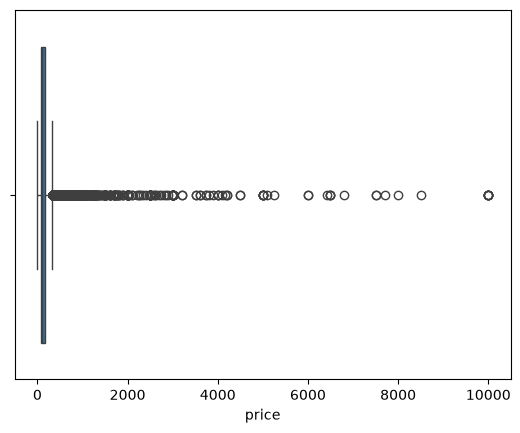

In [7]:
sns.boxplot(x=d["price"])
plt.show()

In [8]:
d["price"].sort_values(ascending=False).head(10)

29238    10000
9151     10000
17692    10000
6530      9999
40433     9999
12342     9999
30268     8500
4377      8000
29662     7703
42523     7500
Name: price, dtype: int64

In [9]:
print(len(d[d["price"] > 500]))
print(len(d[d["price"] > 1000]))

1044
239


In [10]:
print(d["price"].mean())
print(d[d["price"] <= 1000]["price"].mean())

152.7206871868289
141.27984215718513


con 1000 se quitan pocos y el promedio baja bastante

## item 5

In [11]:
d = df.copy()
d["reviews_per_month"] = d["reviews_per_month"].fillna(0)
d["name"] = d["name"].fillna("sin nombre")
d = d[d["price"] <= 1000].copy()
d = d[(d["price"] > 0) & (d["minimum_nights"] <= 365)].copy()
d.shape

(48631, 16)

In [12]:
d["price"].quantile([0.25, 0.5, 0.75])

0.25     69.0
0.50    105.0
0.75    175.0
Name: price, dtype: float64

In [13]:
d["tipo_precio"] = "medio"
d.loc[d["price"] <= 70, "tipo_precio"] = "barato"
d.loc[d["price"] > 150, "tipo_precio"] = "caro"
d["tipo_precio"].value_counts()

tipo_precio
medio     20409
caro      14695
barato    13527
Name: count, dtype: int64

In [14]:
d["minimum_nights"].value_counts().head(10)

minimum_nights
1     12617
2     11667
3      7977
30     3730
4      3295
5      3025
7      2048
6       747
14      560
10      480
Name: count, dtype: int64

hay muchos con 30 noches, uso eso para estancia larga

In [15]:
d["estancia_larga"] = d["minimum_nights"] >= 30

## item 7

In [16]:
d.groupby("neighbourhood_group")["price"].mean()

neighbourhood_group
Bronx             85.361800
Brooklyn         117.872224
Manhattan        178.942743
Queens            94.983021
Staten Island     98.584906
Name: price, dtype: float64

In [17]:
d.groupby("neighbourhood")["price"].mean().sort_values(ascending=False).head()

neighbourhood
Fort Wadsworth       800.000000
Woodrow              700.000000
Tribeca              330.393939
NoHo                 276.246753
Flatiron District    275.052632
Name: price, dtype: float64

esto sale raro porque hay barrios con un solo anuncio, mejor cuento los anuncios por barrio

In [18]:
d.groupby("neighbourhood")["id"].count().sort_values(ascending=False).head()

neighbourhood
Williamsburg          3908
Bedford-Stuyvesant    3699
Harlem                2651
Bushwick              2460
Hell's Kitchen        1951
Name: id, dtype: int64

In [19]:
d.groupby("neighbourhood_group")["availability_365"].mean()

neighbourhood_group
Bronx            165.782369
Brooklyn          99.975942
Manhattan        111.365469
Queens           144.268129
Staten Island    199.765499
Name: availability_365, dtype: float64

In [20]:
d.groupby("tipo_precio")["number_of_reviews"].mean()

tipo_precio
barato    22.696459
caro      20.040082
medio     26.190308
Name: number_of_reviews, dtype: float64